# A2 Comblement automatique des fentes

Les masques PRMI sont tracés en chaînes de rectangles (WinRHIZO Tron). Deux défauts coupent leur squelette, donc faussent la longueur et pénalisent un modèle qui relie les morceaux :
- **fente** : coupure étroite entre deux morceaux du masque, souvent une racine latérale séparée de sa racine principale ;
- **pincement** : deux rectangles d'une même racine qui ne se touchent que par un ou deux pixels.

**L'essentiel**
- **Méthode** (`src/prmi/gaps.py`) : fermeture morphologique (rayon 4 px), dont on ne garde que les **ponts** entre morceaux, et seulement s'ils touchent l'**extrémité** d'un morceau. Deux racines parallèles proches ne sont jamais reliées ; la largeur des racines ne change pas.
- **Validée** contre les masques corrigés à la main : 42 des 49 fentes comblées sont confirmées, 95 pincements bouchés.
- **Appliquée une fois pour toutes** aux masques PRMI du train, du val et du test (`data/processed/masks_combles/`), jamais aux masques corrigés.
- **Ne règle pas les branches parasites** du squelette (environ +14 % de longueur) : à élaguer au moment de mesurer la longueur.

**Règle des extrémités** : extrémité contre extrémité, ou extrémité contre bord : on relie ; bord long contre bord long : jamais. Autour du point de contact, on prend les pixels du morceau dans un rayon de 25 px et leur axe principal ; le contact est une extrémité si presque tous ces pixels sont d'un seul côté.

**Validation** : 127 images avec racine dans les deux versions (train et val). Une fente comblée est confirmée si les morceaux qu'elle relie forment un seul morceau dans le masque corrigé. Limites : un seul annotateur ; lot enrichi en cas difficiles ; la correction ne visait pas que les fentes.

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd

from prmi import gaps, viz
from prmi.dataset import VAL_LARGE, draw_extra

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

pairs = gaps.load_pairs()
print(len(pairs), 'images avec racine dans le masque d\'origine et dans le masque corrigé')

127 images avec racine dans le masque d'origine et dans le masque corrigé


## 1. Taille des fentes

Pour chaque morceau d'origine que la correction manuelle a réuni à un autre : distance au plus proche de ces autres morceaux. Une fermeture de rayon r comble les écarts jusqu'à environ 2r.

count     79.0
mean       7.9
std       16.9
min        2.0
50%        4.1
75%        7.3
90%        8.9
max      134.4
Name: distance, dtype: float64

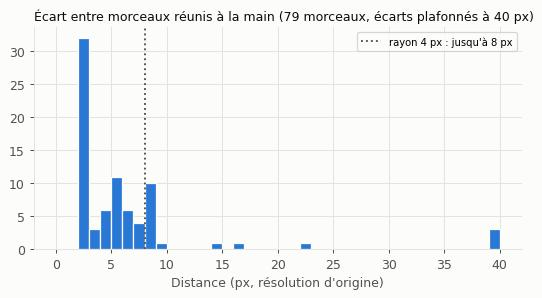

In [ ]:
merges = gaps.manual_merges(pairs)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(merges['distance'].clip(upper=40), bins=40, range=(0, 40), color=viz.ACCENT, edgecolor=viz.SURFACE)
ax.axvline(2 * gaps.RADIUS, color=viz.INK_2, linestyle=':', label=f'rayon {gaps.RADIUS} px : jusqu\'à {2 * gaps.RADIUS} px')
ax.set_title(f'Écart entre morceaux réunis à la main ({len(merges)} morceaux, écarts plafonnés à 40 px)', loc='left', fontsize=10)
ax.set_xlabel('Distance (px, résolution d\'origine)')
ax.legend(fontsize=8)
merges['distance'].describe(percentiles=[0.5, 0.75, 0.9]).round(1)

## 2. Réglage

Morceaux restants (le masque corrigé en a 257), pixels ajoutés et part de ces pixels dans le masque corrigé, fentes comblées et confirmées, pincements bouchés. Les pincements ne changent pas le nombre de morceaux (ils étaient déjà reliés par un ou deux pixels). Environ 1 min.

In [ ]:
table_settings = gaps.compare_settings(pairs, {'fentes seules, rayon 4': (4, 0), 'fentes et pincements, rayon 4': (4, 1),
                                              'fentes et pincements, rayon 6': (6, 1)})
table_settings.round(3)

,morceaux,px ajoutés,part dans le corrigé,fentes comblées,dont confirmées,pincements bouchés
"fentes seules, rayon 4",292.0,2543.0,0.815,49.0,42.0,0.0
"fentes et pincements, rayon 4",292.0,3420.0,0.834,49.0,42.0,95.0
"fentes et pincements, rayon 6",288.0,5102.0,0.741,54.0,46.0,92.0
origine,339.0,NaN,NaN,NaN,NaN,NaN
corrigé,257.0,NaN,NaN,NaN,NaN,NaN


## 3. Contrôle visuel des fentes (rayon 4 px)

Masque d'origine en bleu, ajouts du comblement en orange, masque corrigé à droite. D'abord 10 fentes comblées et confirmées, tirées au hasard ; puis les fentes refusées par la règle des extrémités ; puis les fentes comblées que la correction manuelle n'a pas réunies.

53 fentes candidates : 49 comblées, dont 42 confirmées ; 4 refusées


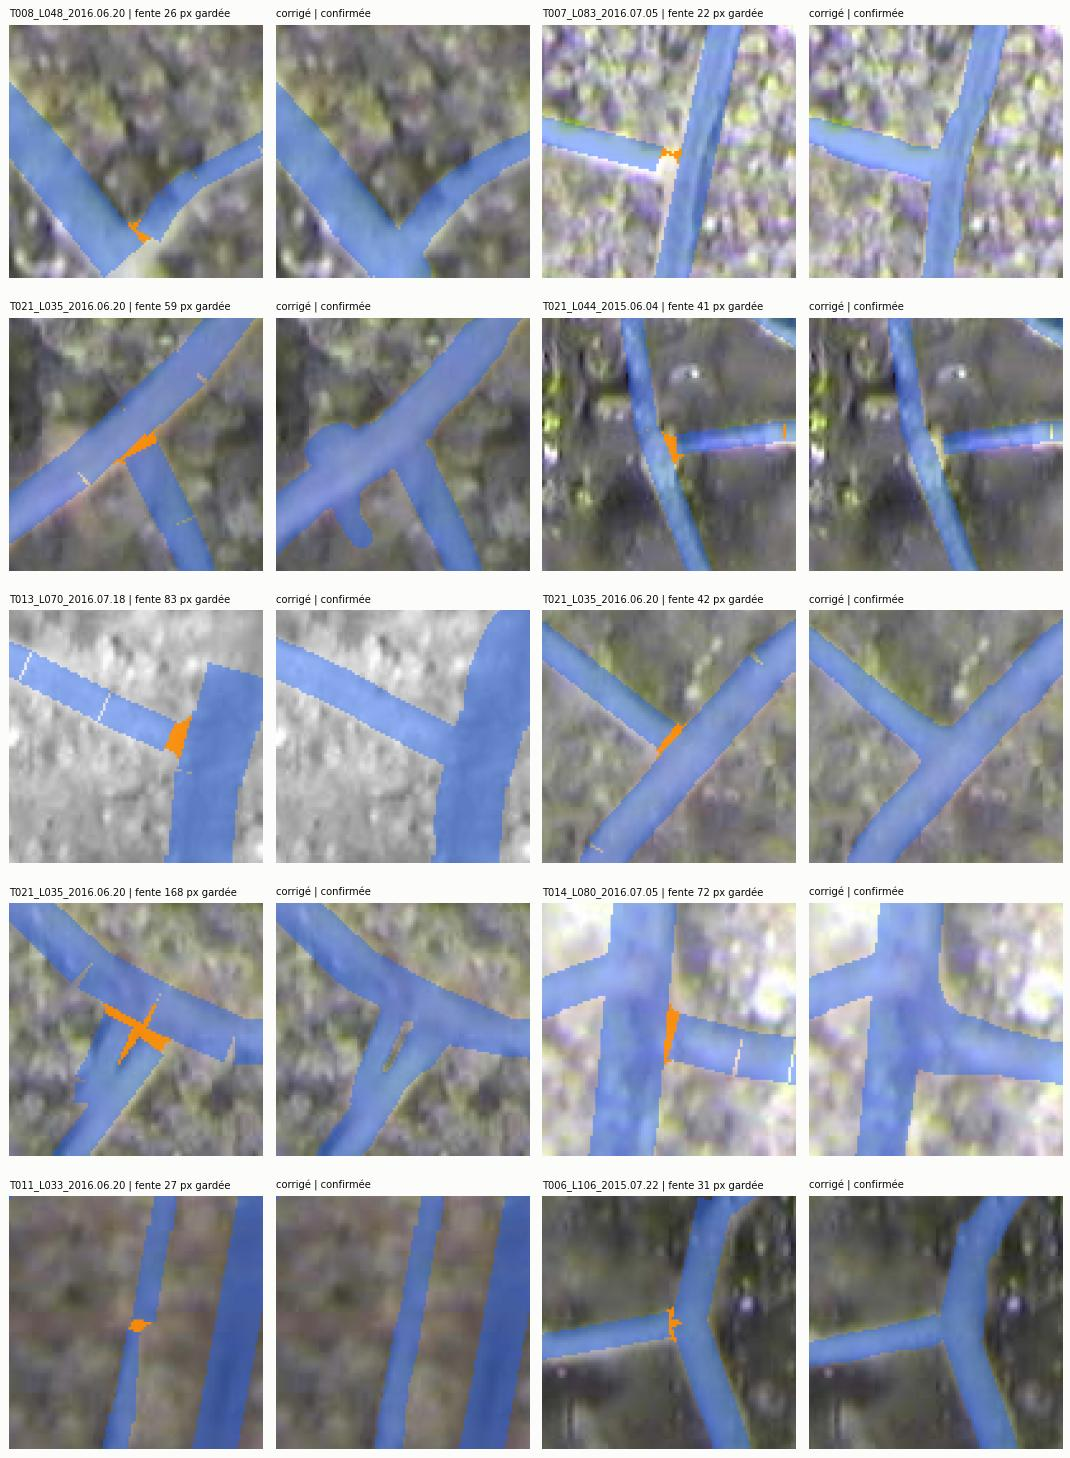

In [ ]:
table = gaps.bridge_table(pairs)
slits = table[table['kind'] == 'fente']
print(len(slits), 'fentes candidates :', int(slits['kept'].sum()), 'comblées, dont', int((slits['kept'] & slits['confirmed']).sum()),
      'confirmées ;', int((~slits['kept']).sum()), 'refusées')
images, titles = gaps.bridge_views(pairs, slits[slits['kept'] & slits['confirmed']].sample(10, random_state=0))
viz.image_grid(images, titles, ncols=4);

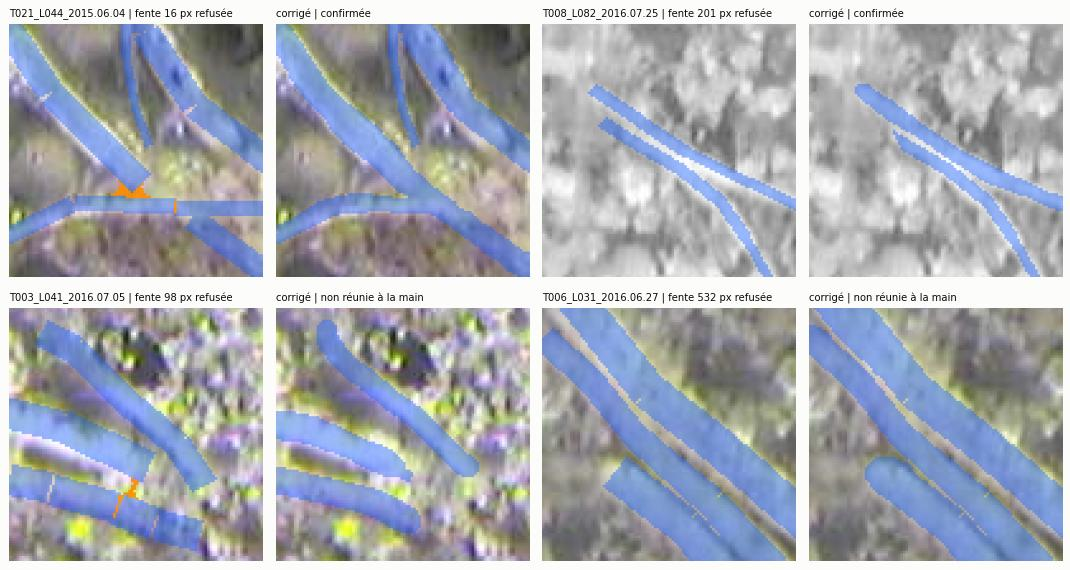

In [ ]:
images, titles = gaps.bridge_views(pairs, slits[~slits['kept']])
viz.image_grid(images, titles, ncols=4);

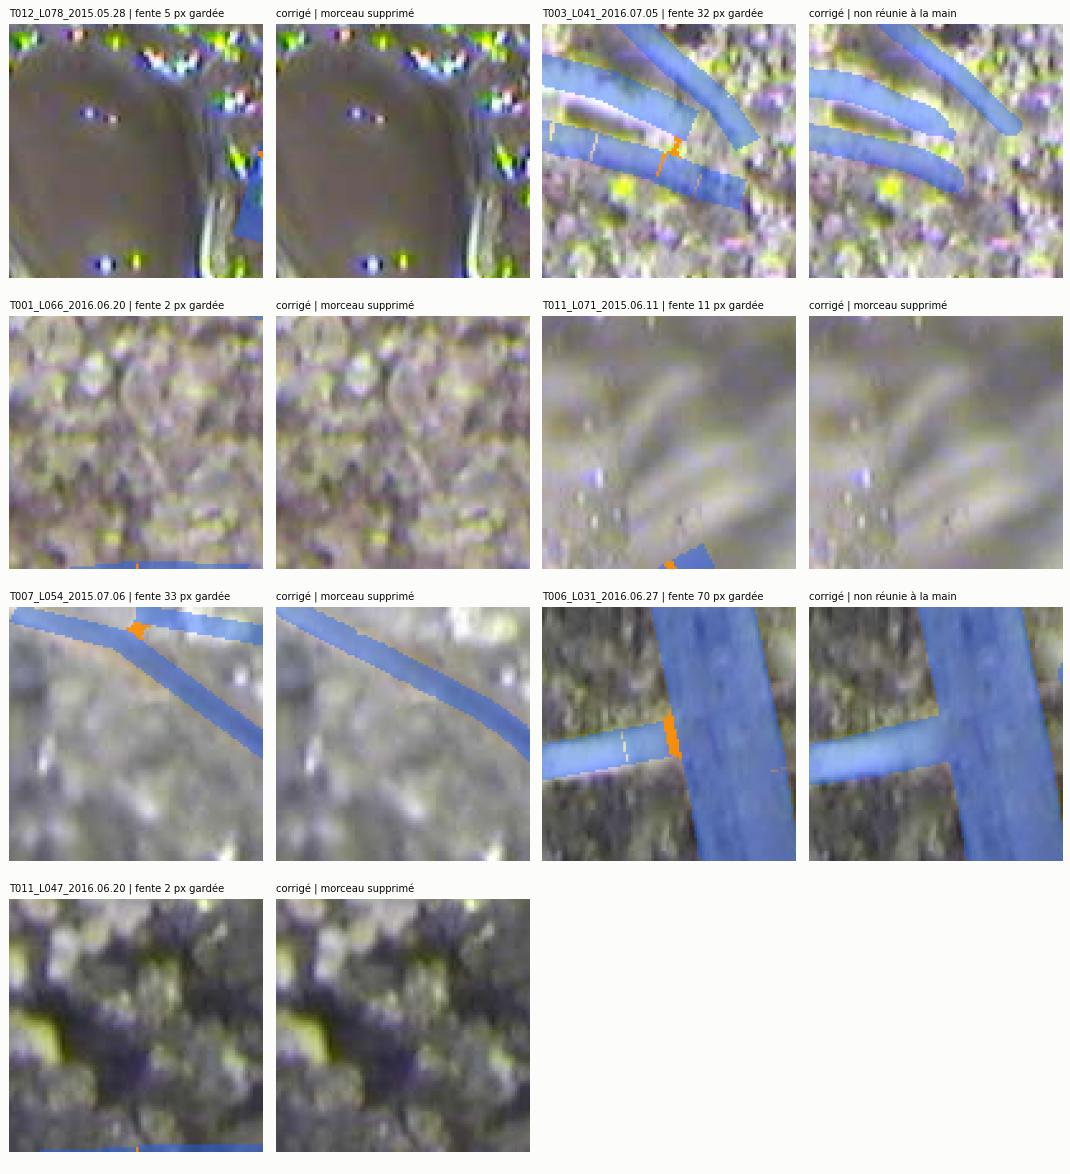

In [ ]:
images, titles = gaps.bridge_views(pairs, slits[slits['kept'] & ~slits['confirmed']])
viz.image_grid(images, titles, ncols=4);

## 4. Contrôle visuel des pincements

12 pincements bouchés, tirés au hasard.

101 pincements candidats, 95 bouchés


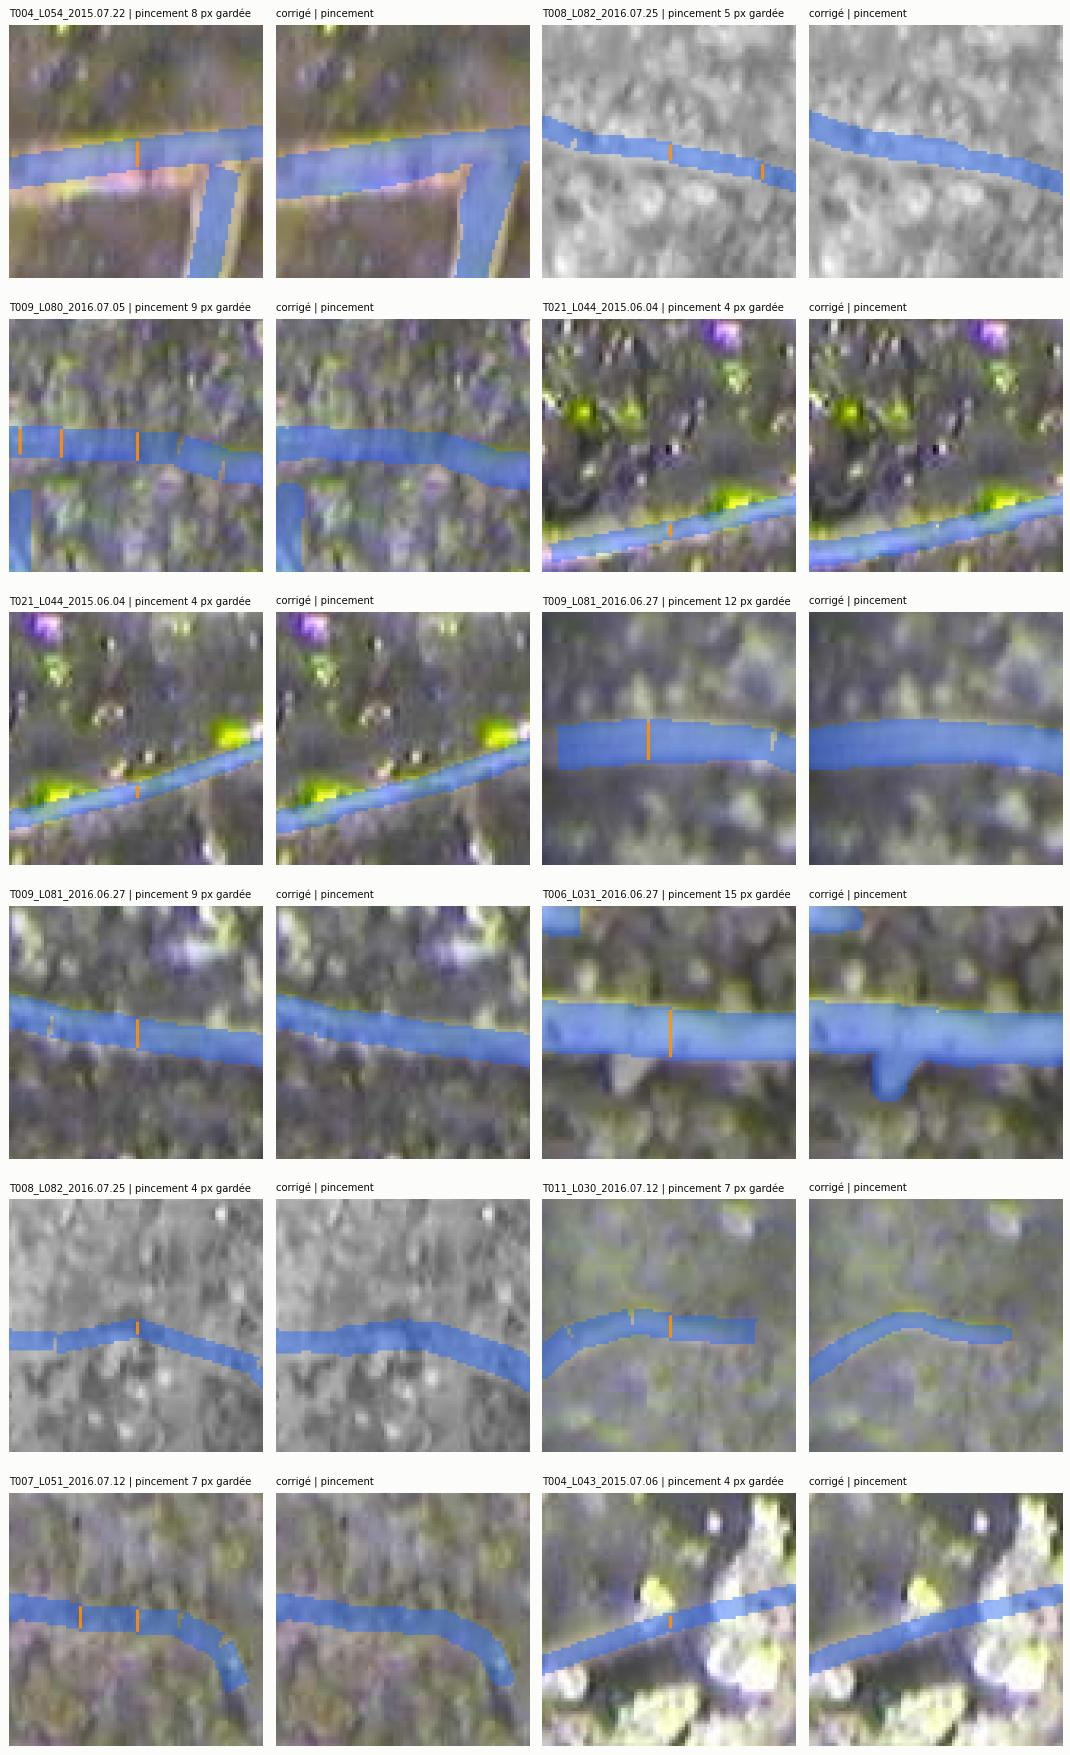

In [ ]:
pinches = table[table['kind'] == 'pincement']
print(len(pinches), 'pincements candidats,', int(pinches['kept'].sum()), 'bouchés')
images, titles = gaps.bridge_views(pairs, pinches[pinches['kept']].sample(12, random_state=0), half=40, zoom=3)
viz.image_grid(images, titles, ncols=4);

## 5. Effet sur le squelette

Longueur du squelette du masque (px) comparée à celle du masque corrigé, et nombre de bouts de squelette. Un excès de longueur et de bouts vient surtout des **petites branches parasites** que les coins des rectangles font pousser sur le squelette : le comblement ne les traite pas. Elles devront être élaguées au moment de mesurer la longueur (phase 4).

In [ ]:
skeletons = gaps.skeleton_table(pairs, {'origine': lambda m: m, 'comblé': gaps.fill_gaps})
rows = {}
for k in ['origine', 'comblé', 'corrigé']:
    excess = (skeletons[f'longueur {k}'] - skeletons['longueur corrigé']) / skeletons['longueur corrigé']
    rows[k] = {'écart de longueur au corrigé (médiane)': excess.median(), 'bouts de squelette': skeletons[f'bouts {k}'].sum()}
pd.DataFrame(rows).T.round(3)

,écart de longueur au corrigé (médiane),bouts de squelette
origine,0.163,2178.0
comblé,0.143,2059.0
corrigé,0.000,777.0


## 6. Ampleur sur les masques d'origine utilisés

Fentes et pincements comblés sur les 851 images d'entraînement en plus (notebook 04) et sur le grand val (essai E3), images avec racine. Masques lus sur la clé (environ 2 min).

In [ ]:
for label, rows in [('851 images d\'entraînement', draw_extra(851)),
                    ('grand val', draw_extra(1000, path=VAL_LARGE, split='val'))]:
    counts = gaps.count_bridges(rows)
    touched = (counts['fentes'] + counts['pincements']) > 0
    print(f"{label} : {len(counts)} images avec racine, {touched.mean():.0%} touchées, "
          f"{counts['fentes'].sum()} fentes, {counts['pincements'].sum()} pincements")

851 images d'entraînement : 478 images avec racine, 34% touchées, 196 fentes, 318 pincements
grand val : 568 images avec racine, 36% touchées, 197 fentes, 432 pincements


## 7. Décision

- Réglage retenu : rayon 4 px, pincements de 1 à 2 px, règle des extrémités.
- Masques comblés enregistrés pour tout le train, le val et le test 150 et 120 DPI (`python -m prmi.gaps` et notebook 07), utilisés pour l'entraînement sur tout le train (notebook 05) et comme référence des grands jeux d'évaluation.
- Reste à faire au moment de mesurer la longueur : élaguer les branches parasites du squelette.